# Convert digHolo `.mat` batches to `.npz`

Camera batches from the older MATLAB workflow are stored as `.mat` files.
This notebook loads each batch and writes a NumPy `.npz` that `processBatch` can read.

Expected camera array: `frames` with shape `(batchCount, height, width)`, `float32`, C-contiguous.
The file in this folder, `Aligment_batch_frames_SLM_relayed_modes.mat`, contains
`frames` with shape `(506, 640, 512)` and dtype `single`.

Other numeric variables in a `.mat` (for example `pixelBuffer`, `coefs`, `fieldR`, `fieldI`, `x`, `y`) are copied through as well. `pixelBuffer` is also saved under the name `frames`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat

DATA_DIR = Path.cwd()
if not any(DATA_DIR.glob("*.mat")) and (DATA_DIR / "data_testing").is_dir():
    DATA_DIR = DATA_DIR / "data_testing"

COMPRESS = False  # True writes a smaller file and takes longer
print(DATA_DIR.resolve())

C:\Users\ModeLabQBI\LAB\algorithms\DigitalHolography\data_testing


In [2]:
SKIP_KEYS = {"__header__", "__version__", "__globals__"}
FRAME_KEYS = ("frames", "pixelBuffer", "frameBuffer")


def _as_frames(array):
    """Camera batch as float32, C-order, shape (batchCount, height, width)."""
    frames = np.asarray(array)
    frames = np.squeeze(frames)
    if frames.ndim == 2:
        frames = frames[np.newaxis, ...]
    if frames.ndim != 3:
        raise ValueError(f"expected a 3D batch, got shape {frames.shape}")
    return np.ascontiguousarray(frames, dtype=np.float32)


def mat_to_npz(mat_path, npz_path=None, compress=False):
    mat_path = Path(mat_path)
    if npz_path is None:
        npz_path = mat_path.with_suffix(".npz")

    raw = loadmat(mat_path)
    arrays = {}
    frame_source = None
    for key, value in raw.items():
        if key in SKIP_KEYS or key.startswith("__"):
            continue
        array = np.asarray(value)
        if key in FRAME_KEYS:
            array = _as_frames(array)
            if frame_source is None:
                arrays["frames"] = array
                frame_source = key
        arrays[key] = array

    if "frames" not in arrays:
        names = ", ".join(arrays) or "(none)"
        raise KeyError(
            f"{mat_path.name} has no frames/pixelBuffer/frameBuffer. Variables: {names}"
        )

    saver = np.savez_compressed if compress else np.savez
    saver(npz_path, **arrays)
    return npz_path, frame_source, arrays


mat_files = sorted(DATA_DIR.glob("*.mat"))
print(f"{len(mat_files)} .mat file(s)")
for path in mat_files:
    print(f"  {path.name}  ({path.stat().st_size / 1e6:.1f} MB)")

1 .mat file(s)
  Aligment_batch_frames_SLM_relayed_modes.mat  (663.2 MB)


In [3]:
converted = []
for mat_path in mat_files:
    npz_path, frame_source, arrays = mat_to_npz(mat_path, compress=COMPRESS)
    frames = arrays["frames"]
    converted.append((npz_path, frames))
    print(f"{mat_path.name} -> {npz_path.name}")
    print(f"  frames from '{frame_source}': shape={frames.shape} dtype={frames.dtype} contiguous={frames.flags['C_CONTIGUOUS']}")
    extras = [key for key in arrays if key != "frames"]
    if extras:
        print("  also saved:", ", ".join(extras))

Aligment_batch_frames_SLM_relayed_modes.mat -> Aligment_batch_frames_SLM_relayed_modes.npz
  frames from 'frames': shape=(506, 640, 512) dtype=float32 contiguous=True


Aligment_batch_frames_SLM_relayed_modes.npz keys: ['frames']
frames (506, 640, 512) float32 min 0.0 max 2325.0


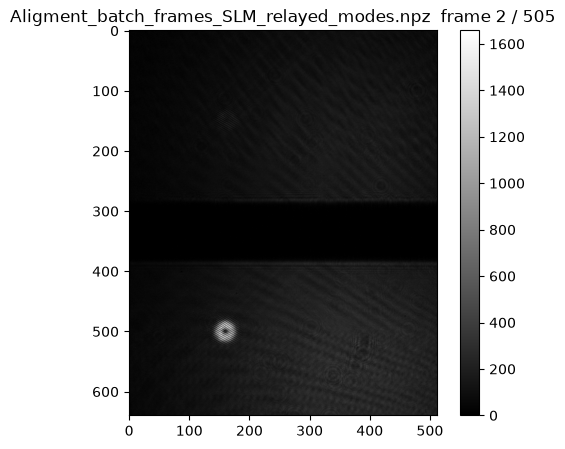

In [6]:
npz_path, _ = converted[0]
with np.load(npz_path) as data:
    frames = data["frames"]
    print(npz_path.name, "keys:", list(data.files))

print("frames", frames.shape, frames.dtype, "min", float(frames.min()), "max", float(frames.max()))

frame_index = 2
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(frames[frame_index], cmap="gray")
ax.set_title(f"{npz_path.name}  frame {frame_index} / {frames.shape[0] - 1}")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.show()